# Vehicle CO₂ Emission Prediction Using Multiple Linear Regression

## Project Objective
Predict vehicle CO₂ emissions (g/km) using Engine size, Cylinders, City fuel consumption, and Highway fuel consumption.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
sns.set_theme(style="whitegrid")


In [2]:
df = pd.read_csv("my1995-2014-fuel-consumption-ratings-5-cycle.csv")
df.head()


,Model year,Make,Model,Vehicle class,Engine size (L),Cylinders,Transmission,Fuel type,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating
0,1995,Acura,Integra,Subcompact,1.8,4,A4,X,11.6,8.3,10.1,28,232,NaN,NaN
1,1995,Acura,Integra,Subcompact,1.8,4,M5,X,11.0,8.3,9.8,29,225,NaN,NaN
2,1995,Acura,Integra GS-R,Subcompact,1.8,4,M5,Z,10.8,8.3,9.7,29,223,NaN,NaN
3,1995,Acura,Legend,Compact,3.2,6,A4,Z,14.2,10.5,12.5,23,288,NaN,NaN
4,1995,Acura,Legend Coupe,Compact,3.2,6,A4,Z,14.6,11.0,13.0,22,299,NaN,NaN


## 1. Understand the Dataset

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())
df.info()


Number of rows: 17853
Number of columns: 15

Column names:
['Model year', 'Make', 'Model', 'Vehicle class', 'Engine size (L)', 'Cylinders', 'Transmission', 'Fuel type', 'City (L/100 km)', 'Highway (L/100 km)', 'Combined (L/100 km)', 'Combined (mpg)', 'CO2 emissions (g/km)', 'CO2 rating', 'Smog rating']
<class 'pandas.DataFrame'>
RangeIndex: 17853 entries, 0 to 17852
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Model year            17853 non-null  int64  
 1   Make                  17853 non-null  str    
 2   Model                 17853 non-null  str    
 3   Vehicle class         17853 non-null  str    
 4   Engine size (L)       17853 non-null  float64
 5   Cylinders             17853 non-null  int64  
 6   Transmission          17853 non-null  str    
 7   Fuel type             17853 non-null  str    
 8   City (L/100 km)       17853 non-null  float64
 9   Highway (L/100 km)    17853 non-

## 2. Select Project Variables

Target: **CO2 emissions (g/km)**

Predictors: Engine size (L), Cylinders, City (L/100 km), Highway (L/100 km).

In [4]:
project_data = df[["Engine size (L)", "Cylinders", "City (L/100 km)", "Highway (L/100 km)", "CO2 emissions (g/km)"]].copy()
project_data.head()


,Engine size (L),Cylinders,City (L/100 km),Highway (L/100 km),CO2 emissions (g/km)
0,1.8,4,11.6,8.3,232
1,1.8,4,11.0,8.3,225
2,1.8,4,10.8,8.3,223
3,3.2,6,14.2,10.5,288
4,3.2,6,14.6,11.0,299


In [5]:
project_data.isnull().sum()


Engine size (L)         0
Cylinders               0
City (L/100 km)         0
Highway (L/100 km)      0
CO2 emissions (g/km)    0
dtype: int64

In [6]:
project_data = project_data.dropna()
print("Observations after removing missing values:", len(project_data))


Observations after removing missing values: 17853


In [7]:
project_data.describe()


,Engine size (L),Cylinders,City (L/100 km),Highway (L/100 km),CO2 emissions (g/km)
count,17853.000000,17853.000000,17853.000000,17853.000000,17853.000000
mean,3.449885,5.948468,14.547393,10.478805,287.205176
std,1.326597,1.752572,3.709201,2.662348,65.637391
min,0.800000,2.000000,4.500000,4.000000,104.000000
25%,2.400000,4.000000,12.000000,8.700000,242.000000
50%,3.300000,6.000000,14.000000,9.800000,278.000000
75%,4.300000,8.000000,16.700000,12.100000,329.000000
max,8.400000,16.000000,33.300000,22.100000,633.000000


In [8]:
print("Number of duplicate rows:", project_data.duplicated().sum())


Number of duplicate rows: 10728


## 3. Exploratory Data Analysis

### Distribution of CO₂ Emissions

C:\Users\alok\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


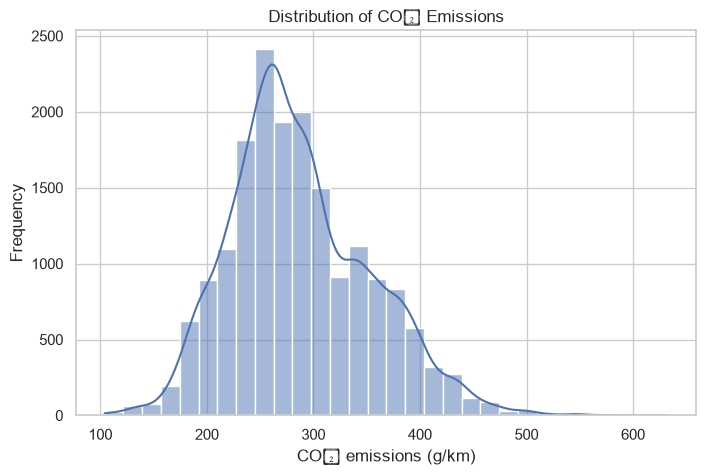

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(project_data["CO2 emissions (g/km)"], bins=30, kde=True)
plt.xlabel("CO₂ emissions (g/km)")
plt.ylabel("Frequency")
plt.title("Distribution of CO₂ Emissions")
plt.show()


### Engine Size vs CO₂

C:\Users\alok\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


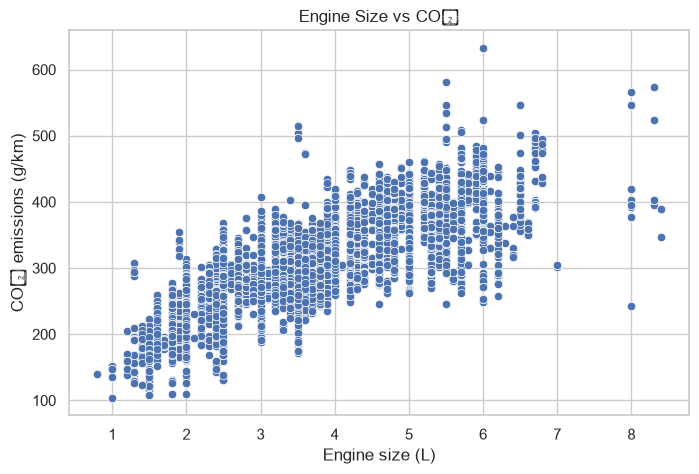

In [10]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=project_data, x="Engine size (L)", y="CO2 emissions (g/km)")
plt.xlabel("Engine size (L)")
plt.ylabel("CO₂ emissions (g/km)")
plt.title("Engine Size vs CO₂")
plt.show()


### Cylinders vs CO₂

C:\Users\alok\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


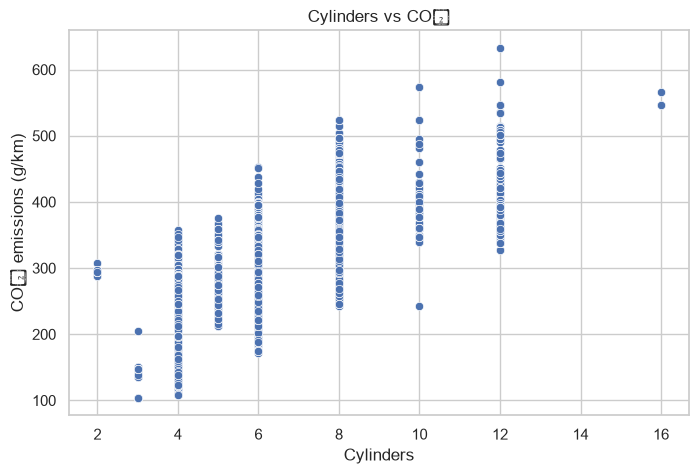

In [11]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=project_data, x="Cylinders", y="CO2 emissions (g/km)")
plt.xlabel("Cylinders")
plt.ylabel("CO₂ emissions (g/km)")
plt.title("Cylinders vs CO₂")
plt.show()


### City Fuel Consumption vs CO₂

C:\Users\alok\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


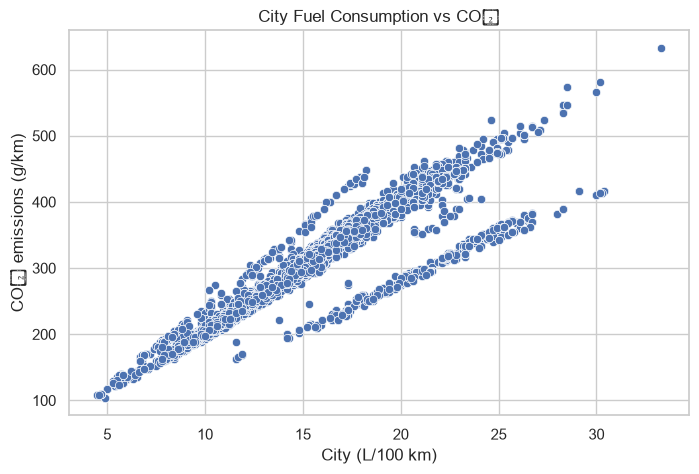

In [12]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=project_data, x="City (L/100 km)", y="CO2 emissions (g/km)")
plt.xlabel("City (L/100 km)")
plt.ylabel("CO₂ emissions (g/km)")
plt.title("City Fuel Consumption vs CO₂")
plt.show()


### Highway Fuel Consumption vs CO₂

C:\Users\alok\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


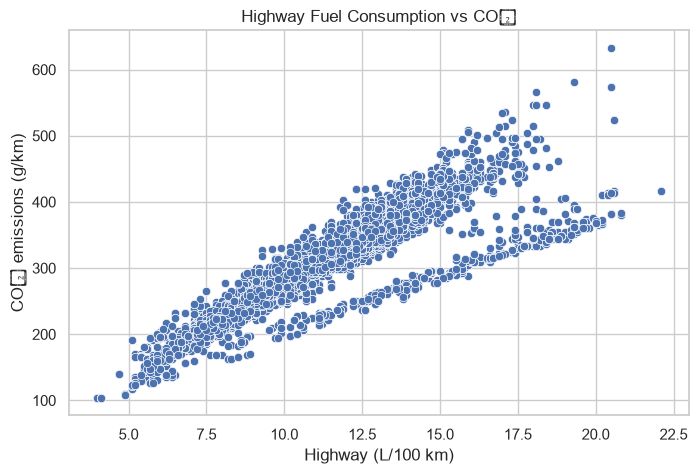

In [13]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=project_data, x="Highway (L/100 km)", y="CO2 emissions (g/km)")
plt.xlabel("Highway (L/100 km)")
plt.ylabel("CO₂ emissions (g/km)")
plt.title("Highway Fuel Consumption vs CO₂")
plt.show()


## 4. Correlation Analysis
Correlation ranges from -1 to +1 and measures the strength and direction of a linear relationship.

In [14]:
correlation = project_data.corr()
correlation


,Engine size (L),Cylinders,City (L/100 km),Highway (L/100 km),CO2 emissions (g/km)
Engine size (L),1.000000,0.901907,0.822870,0.770253,0.827318
Cylinders,0.901907,1.000000,0.785877,0.699369,0.784474
City (L/100 km),0.822870,0.785877,1.000000,0.953111,0.921097
Highway (L/100 km),0.770253,0.699369,0.953111,1.000000,0.902499
CO2 emissions (g/km),0.827318,0.784474,0.921097,0.902499,1.000000


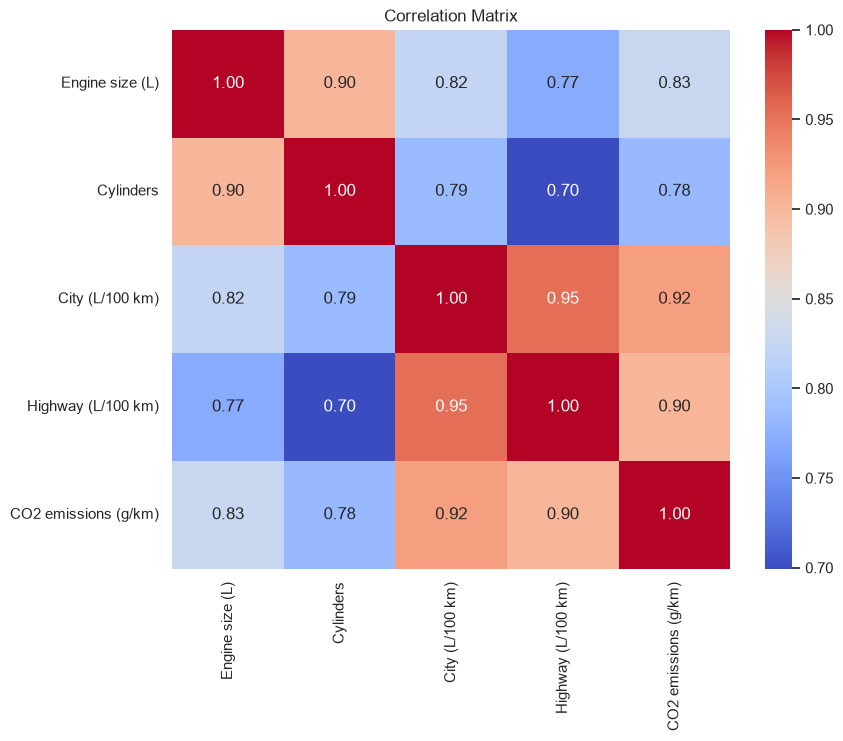

In [15]:
plt.figure(figsize=(9,7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


## 5. Define X and y

In [16]:
X = project_data[["Engine size (L)", "Cylinders", "City (L/100 km)", "Highway (L/100 km)"]]
y = project_data["CO2 emissions (g/km)"]
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (17853, 4)
y shape: (17853,)


## 6. Train-Test Split
80% training and 20% testing data.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))


Training observations: 14282
Testing observations: 3571


## 7. Multiple Linear Regression
CO₂ = β₀ + β₁ Engine Size + β₂ Cylinders + β₃ City Fuel + β₄ Highway Fuel + ε

In [18]:
model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[7.24,3.94,6.69,8.79]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Engine size (L)','Cylinders','City (L/100 km)','Highway (L/100 km)']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,49.34
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [19]:
print("Intercept:", model.intercept_)
coefficients = pd.DataFrame({"Variable": X.columns, "Coefficient": model.coef_})
coefficients


Intercept: 49.336490787283935


,Variable,Coefficient
0,Engine size (L),7.241380
1,Cylinders,3.935714
2,City (L/100 km),6.693442
3,Highway (L/100 km),8.790395


In [20]:
print(f"CO2 = {model.intercept_:.3f} + ({model.coef_[0]:.3f})×Engine Size + ({model.coef_[1]:.3f})×Cylinders + ({model.coef_[2]:.3f})×City Fuel + ({model.coef_[3]:.3f})×Highway Fuel")


CO2 = 49.336 + (7.241)×Engine Size + (3.936)×Cylinders + (6.693)×City Fuel + (8.790)×Highway Fuel


## 8. OLS Statistical Inference

In [21]:
X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())


                             OLS Regression Results                             
Dep. Variable:     CO2 emissions (g/km)   R-squared:                       0.874
Model:                              OLS   Adj. R-squared:                  0.874
Method:                   Least Squares   F-statistic:                 2.479e+04
Date:                  Tue, 06 Oct 2026   Prob (F-statistic):               0.00
Time:                          20:02:45   Log-Likelihood:                -65232.
No. Observations:                 14282   AIC:                         1.305e+05
Df Residuals:                     14277   BIC:                         1.305e+05
Df Model:                             4                                         
Covariance Type:              nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const           

In [22]:
print("R-squared:", ols_model.rsquared)
print("Adjusted R-squared:", ols_model.rsquared_adj)


R-squared: 0.8741624738956847
Adjusted R-squared: 0.8741272178822073


In [23]:
p_values = pd.DataFrame({"Variable": ols_model.params.index, "Coefficient": ols_model.params.values, "P-value": ols_model.pvalues.values})
p_values


,Variable,Coefficient,P-value
0,const,49.336491,0.000000e+00
1,Engine size (L),7.241380,1.599724e-79
2,Cylinders,3.935714,1.076547e-46
3,City (L/100 km),6.693442,1.908805e-215
4,Highway (L/100 km),8.790395,9.851870e-250


In [24]:
confidence_intervals = pd.DataFrame(ols_model.conf_int(), columns=["Lower 95%", "Upper 95%"], index=ols_model.params.index)
confidence_intervals


,Lower 95%,Upper 95%
const,NaN,NaN
Engine size (L),NaN,NaN
Cylinders,NaN,NaN
City (L/100 km),NaN,NaN
Highway (L/100 km),NaN,NaN


## 9. Test Predictions and Evaluation

In [25]:
y_pred = model.predict(X_test)
predictions = pd.DataFrame({"Actual CO2": y_test.values, "Predicted CO2": y_pred})
predictions.head(10)


,Actual CO2,Predicted CO2
0,235,234.246652
1,189,199.358596
2,334,318.052525
3,357,332.991772
4,299,272.722534
5,271,269.938618
6,269,273.309354
7,230,240.679285
8,304,298.802576
9,175,190.182938


In [26]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("RMSE:", rmse)
print("Test R²:", r2)


MAE: 14.092185602848614
RMSE: 23.494920534396677
Test R²: 0.8711032755782488


In [27]:
results = pd.DataFrame({"Metric": ["MAE", "RMSE", "R²"], "Value": [mae, rmse, r2]})
results


,Metric,Value
0,MAE,14.092186
1,RMSE,23.494921
2,R²,0.871103


C:\Users\alok\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


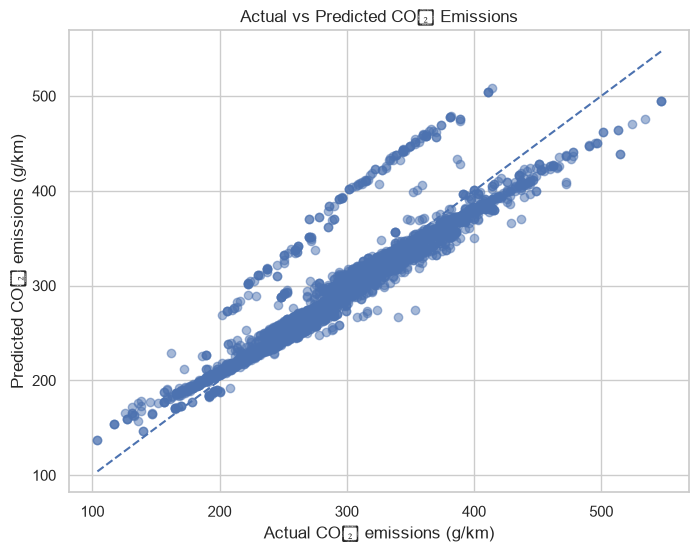

In [28]:
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Actual CO₂ emissions (g/km)")
plt.ylabel("Predicted CO₂ emissions (g/km)")
plt.title("Actual vs Predicted CO₂ Emissions")
plt.show()


## 10. Residual Analysis

In [29]:
residuals = y_test - y_pred
print(residuals.head())


13152     0.753348
8846    -10.358596
1261     15.947475
3964     24.008228
2078     26.277466
Name: CO2 emissions (g/km), dtype: float64


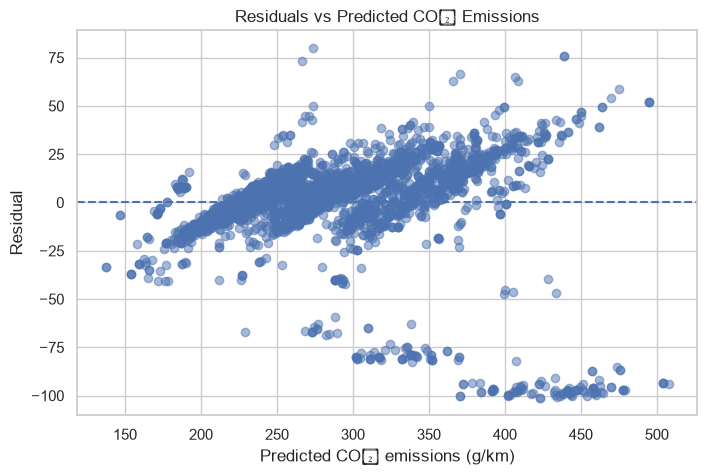

In [30]:
plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted CO₂ emissions (g/km)")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted CO₂ Emissions")
plt.show()


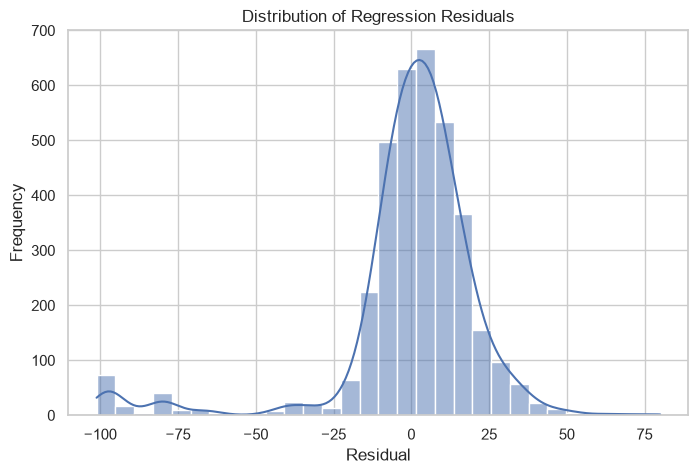

In [31]:
plt.figure(figsize=(8,5))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Regression Residuals")
plt.show()


## 11. Multicollinearity / VIF
VIF assesses multicollinearity among predictors. Values around 1 indicate little multicollinearity; larger values indicate greater concern.

In [32]:
X_vif = sm.add_constant(X)
vif = pd.DataFrame()
vif["Variable"] = X_vif.columns
vif["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif


,Variable,VIF
0,const,22.629713
1,Engine size (L),6.745892
2,Cylinders,6.086709
3,City (L/100 km),15.719048
4,Highway (L/100 km),12.086674


## 12. Overall Model Summary

In [33]:
model_summary = pd.DataFrame({"Metric": ["Training R²", "Adjusted R²", "Test R²", "MAE", "RMSE"], "Value": [ols_model.rsquared, ols_model.rsquared_adj, r2, mae, rmse]})
model_summary


,Metric,Value
0,Training R²,0.874162
1,Adjusted R²,0.874127
2,Test R²,0.871103
3,MAE,14.092186
4,RMSE,23.494921


# 13. Final Conclusion

This project developed a Multiple Linear Regression model to predict vehicle CO₂ emissions in grams per kilometre using engine size, number of cylinders, city fuel consumption, and highway fuel consumption. Exploratory analysis, correlation analysis, regression inference, test-set evaluation, residual analysis, and VIF were used to understand and assess the model. The project demonstrates how multiple linear regression can provide both prediction and interpretable statistical relationships for vehicle emissions data.

## Interview Summary

“I worked on a vehicle CO₂ emission prediction project using Multiple Linear Regression. I used engine size, number of cylinders, city fuel consumption, and highway fuel consumption as predictors and CO₂ emissions in grams per kilometre as the target. I performed EDA and correlation analysis, fitted an MLR model using an 80:20 train-test split, evaluated it using R², MAE and RMSE, examined coefficients and p-values using OLS, and checked residuals and multicollinearity using VIF.”